In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/wholesale_customers.csv")

In [3]:
# Categorical features
categorical_features = ["Channel", "Region"]

In [4]:
# Numerical features
numerical_features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

In [5]:
# Separate numerical spending data
X = df[numerical_features].copy()
print(X.head())

   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0  12669  9656     7561     214              2674        1338
1   7057  9810     9568    1762              3293        1776
2   6353  8808     7684    2405              3516        7844
3  13265  1196     4221    6404               507        1788
4  22615  5410     7198    3915              1777        5185


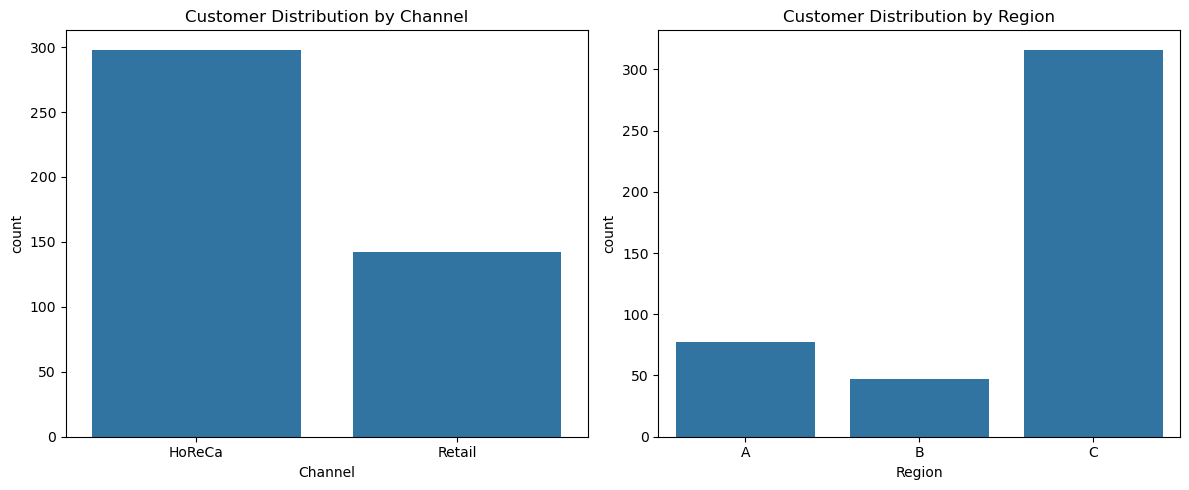

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x="Channel", ax=axes[0])
axes[0].set_title("Customer Distribution by Channel")
axes[0].set_xticks([0, 1], ["HoReCa", "Retail"]) # (Hotels, Restaurants, Cafes) and Retails are the grouped customer distributions 

sns.countplot(data=df, x="Region", ax=axes[1])
axes[1].set_title("Customer Distribution by Region")
axes[1].set_xticks([0, 1, 2], ["A", "B", "C"])

plt.tight_layout()
plt.show()

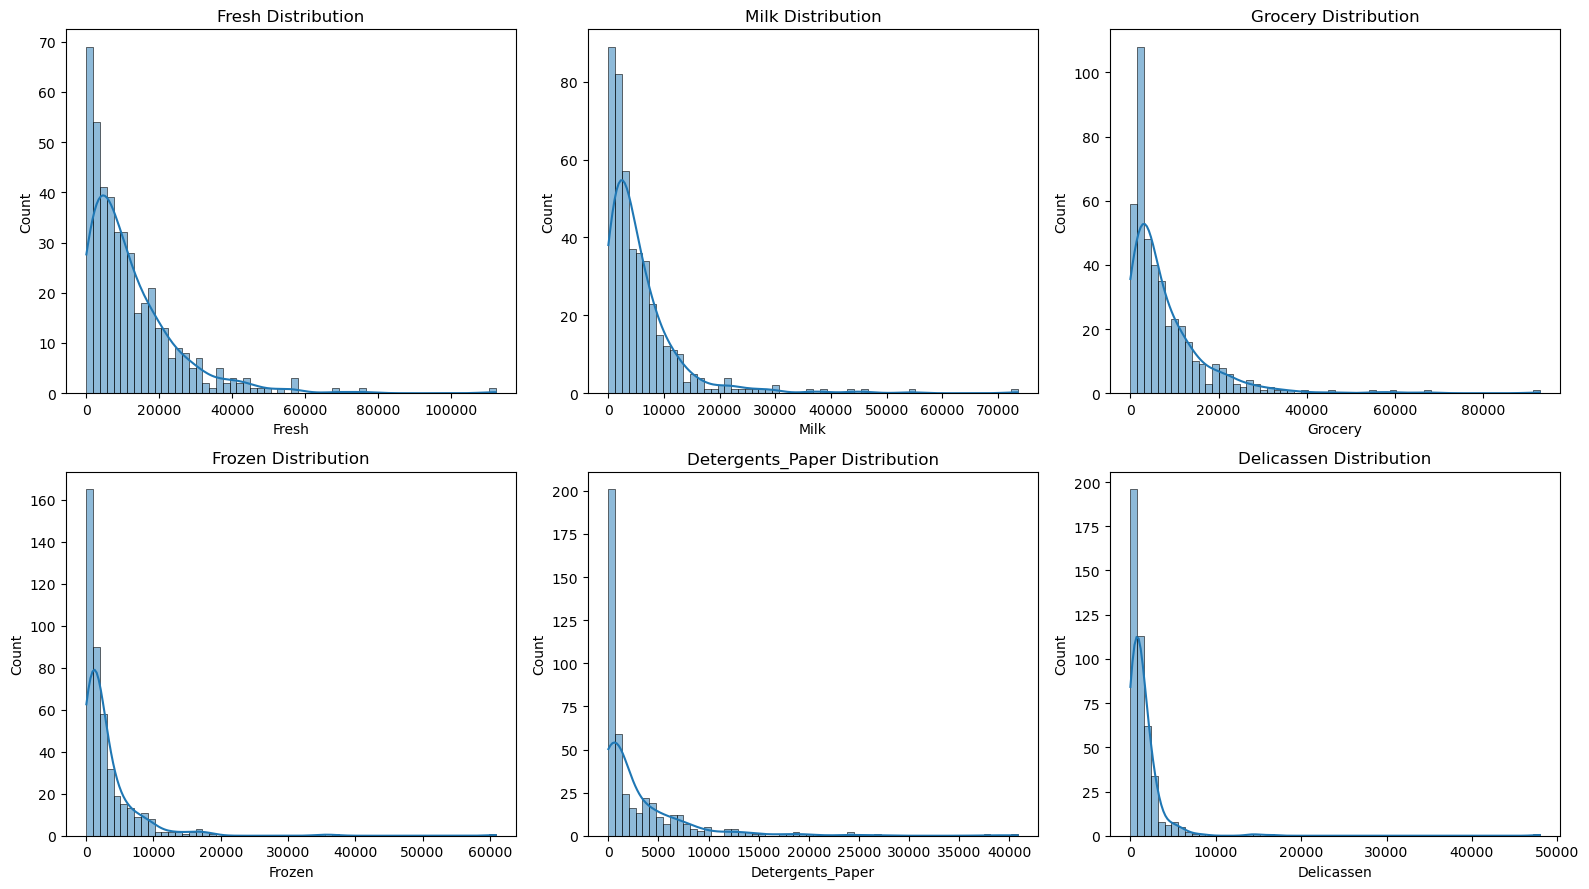

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))    # creates canvas 2x3

# converts to a 1D array for easier looping. pairs each column name in numerical_features with a chart axes.
for feature, ax in zip(numerical_features, axes.flatten()):
    sns.histplot(     # creates histogram
        data=X,       # look at dF X and plot the values of the needed feature
        x=feature,
        bins=60,      # data range
        kde=True,     # kernel density estimate
        ax=ax         # refers to chart axes on where to draw
    )

    ax.set_title(f"{feature} Distribution") 

plt.tight_layout()
plt.show()

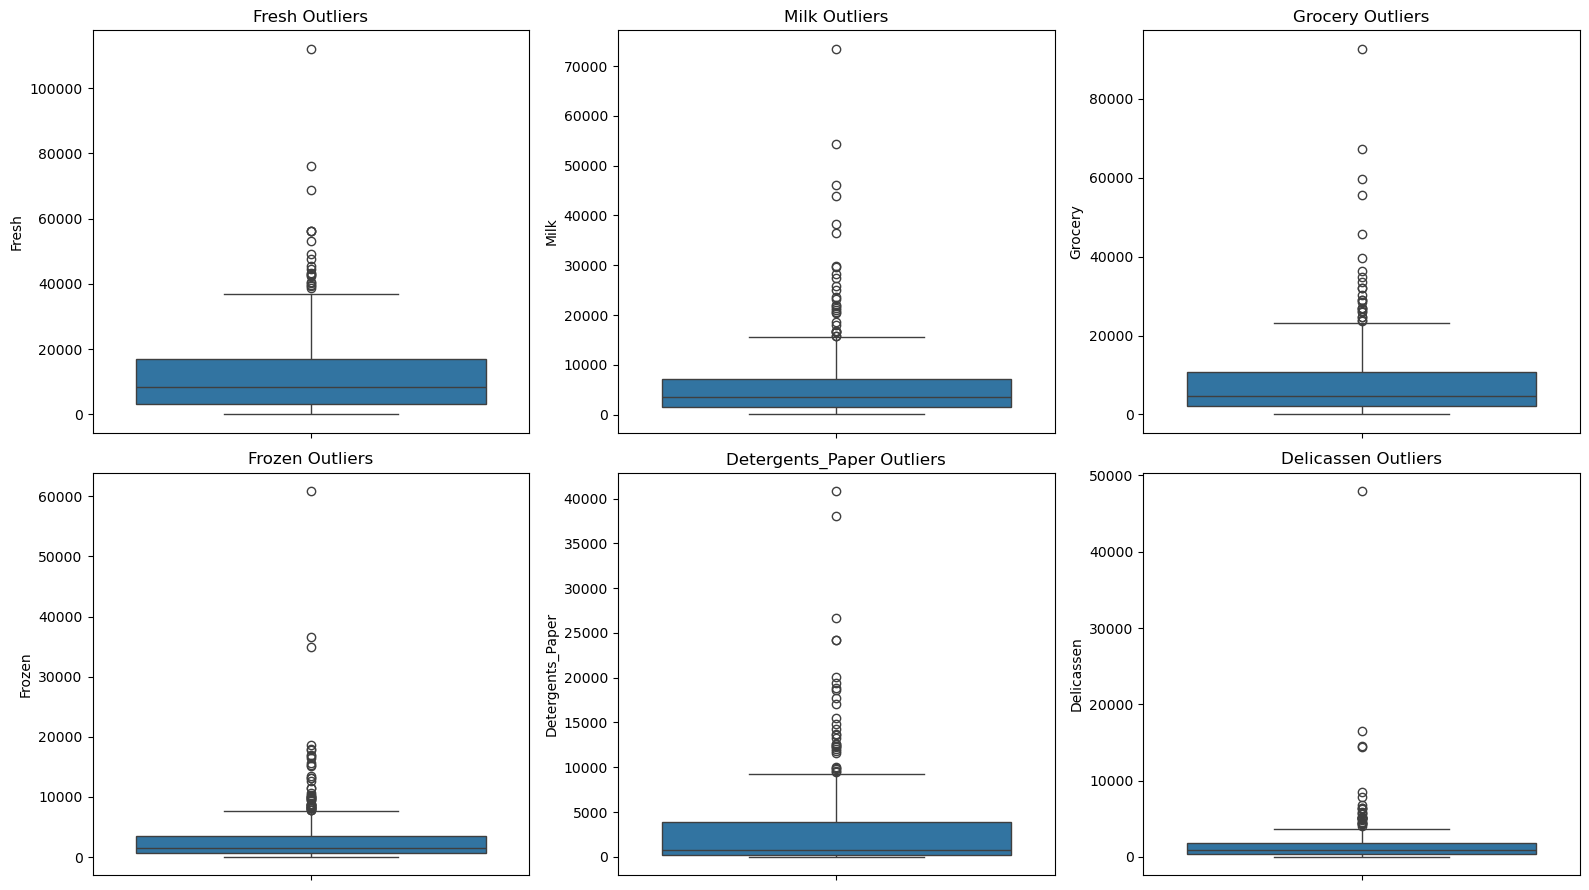

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for feature, ax in zip(numerical_features, axes.flatten()):
    sns.boxplot(
        data=X,
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} Outliers")

plt.tight_layout()
plt.show()

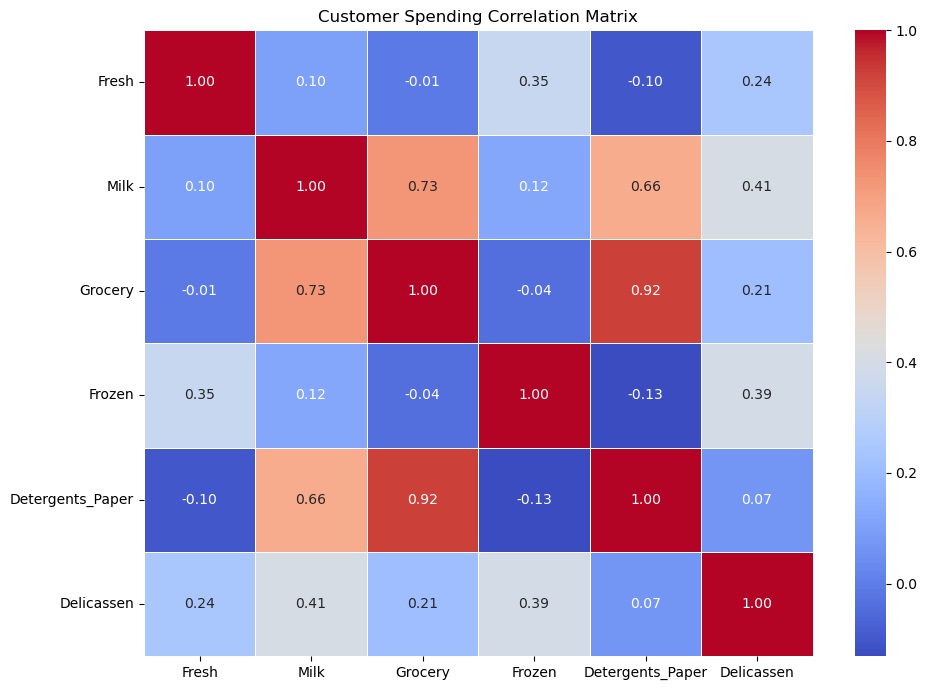

In [13]:
correlation_matrix = X.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Customer Spending Correlation Matrix")
plt.tight_layout()
plt.show()